# Системы поддержки принятия решений

**Тема: «Упражнения 3.1–3.10. Смешанная целочисленная оптимизация»**

Источник постановок: глава 3 предоставленного пособия `milo.pdf`, упражнения на с. 135–140. Используются бинарные и целочисленные переменные, логические ограничения и линеаризация методом большого M. Численные примеры, которых нет в источнике, отдельно обозначены в разделах «Дано».

**Оглавление**

| Задача | Тема |
|:---|:---|
| 3.1 | Максимальное покрытие, сравнение моделей, лексикографическая оптимизация и граница Парето |
| 3.2 | Судоку и проверка единственности |
| 3.3 | Выбор проектов с логическими связями |
| 3.4 | Производство с фиксированными затратами |
| 3.5 | Размещение машин скорой помощи |
| 3.6 | Размещение пожарных депо |
| 3.7 | Планирование приготовления блюд |
| 3.8 | Дробное равенство и логарифмическая линеаризация |
| 3.9 | Поощрение выполнения ограничений |
| 3.10 | Закупки со скидкой на весь заказ |


In [1]:
import pyomo.environ as pyo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from time import perf_counter

pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", "{:,.4f}".format)
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 120,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.2,
    "axes.axisbelow": True,
})

solver_name = None
for name in ("appsi_highs", "highs", "cbc"):
    candidate = pyo.SolverFactory(name)
    if candidate.available(exception_flag=False):
        solver_name = name
        break

if solver_name is None:
    raise RuntimeError("Установите решатель: python -m pip install highspy")

def make_solver():
    solver = pyo.SolverFactory(solver_name)
    if solver_name in ("appsi_highs", "highs"):
        solver.options["mip_rel_gap"] = 0
    else:
        solver.options["ratioGap"] = 0
    return solver

def solve_model(model):
    result = make_solver().solve(model, tee=False)
    pyo.assert_optimal_termination(result)
    return result

print(f"Решатель: {solver_name}")


Решатель: appsi_highs


## Задача 3.1

### Условие

Вспомните Пример 3.10 и предположите, что тот же поставщик имеет ограниченный бюджет на строительство предприятий: может быть построено только заданное количество $p$ предприятий. Кроме того, потенциальные клиенты будут покупать у этого поставщика только в том случае, если предприятие находится в пределах заданного порогового расстояния $S$ от ближайшего к ним объекта. Простой пример должен убедить вас в том, что обслуживание всех клиентов в данном случае может оказаться невозможным. Поэтому поставщик дифференцирует потенциальных клиентов по степени важности, присваивая каждому определенный вес. Поскольку обслужить всех клиентов не представляется возможным, цель состоит в максимизации суммарного веса обслуженных клиентов для заданного количества построенных предприятий.

(a) Покажите, как можно адаптировать модели из Примера 3.10 для решения этой задачи. Вы должны получить две модели: агрегированную (которую вы видели в Примере 3.10, но в более слабой версии) и дезагрегированную (которую вы видели далее).

(b) Модель из предыдущего вопроса может быть существенно упрощена: изучите известную статью [CR74] по так называемой задаче о максимальном покрытии (maximum covering model), чтобы узнать, как выразить ее с использованием одиночных индексов. Реализуйте эти три модели и проанализируйте их масштабируемость с точки зрения размера экземпляров на случайно сгенерированных задачах. Что вы замечаете?

(c) Обратите внимание, что модели, включая модель из [CR74], устанавливают ровно $p$ предприятий. Однако может случиться так, что максимальное достижимое покрытие составит менее $100\%$, даже если построить абсолютно все предприятия. Покажите, как модифицировать модели, чтобы преследовать две цели в строгом лексикографическом порядке: сначала максимизировать покрытие, а затем, для этого максимального покрытия, минимизировать количество построенных предприятий, оставаясь при этом в рамках бюджета.

(d) Подход с лексикографической оптимизацией из предыдущего пункта был специфическим способом работы с компромиссом (trade-off) между затратами и выгодами. Другой распространенный способ — определить так называемую эффективную границу или границу Парето для наибольшего достижимого покрытия для каждого бюджета. Определите эту границу для выбранного вами экземпляра этой задачи.

### Дано

В источнике заданы только обозначения. Следующие координаты в километрах и веса выбраны для воспроизводимого учебного примера. Расстояние евклидово, $S=2{,}4$ км, бюджет $p=4$ предприятия; стоимость одного предприятия принята за одну единицу бюджета.

| Клиент $i$ | Координаты | Вес $w_i$ | Площадка $j$ | Координаты |
|---:|:---:|---:|---:|:---:|
| 1 | (0,5; 0,5) | 9 | 1 | (1; 1) |
| 2 | (1,5; 2) | 7 | 2 | (2; 1) |
| 3 | (2,5; 1) | 6 | 3 | (7; 1) |
| 4 | (6,5; 0,5) | 8 | 4 | (8; 1) |
| 5 | (7,5; 2) | 10 | 5 | (4; 6) |
| 6 | (8,5; 1) | 5 | 6 | (5; 6) |
| 7 | (3,5; 5,5) | 11 | | |
| 8 | (4,5; 7) | 6 | | |
| 9 | (5,5; 5,5) | 8 | | |
| 10 | (4; 3) | 4 | | |
| 11 | (4; 9) | 3 | | |
| 12 | (11; 8) | 12 | | |

Для сравнения масштабируемости дополнительно генерируются три экземпляра $(|I|,|J|)=(30,10),(60,20),(120,40)$. Координаты равномерны на квадрате $[0,100]^2$, веса — целые от 1 до 20, $S=25$, $p=\max(1,\lfloor |J|/6\rfloor)$. Фиксируются seed 310, 311, 312. Это иллюстративный эксперимент с одним экземпляром каждого размера; время зависит от оборудования и запуска.

### Математическая модель

Пусть $I$ — клиенты, $J$ — площадки, $N_i=\{j:d_{ij}\le S\}$, $E=\{(i,j):j\in N_i\}$, $m=|I|$. Во всех моделях $x_j\in\{0,1\}$ (`Binary`) означает строительство предприятия.

**(a) Модели с назначениями.** Переменная $y_{ij}\in\{0,1\}$ (`Binary`), $(i,j)\in E$, означает обслуживание клиента $i$ предприятием $j$. Общая часть:

$$\max W=\sum_{(i,j)\in E}w_i y_{ij},\qquad
\sum_{j\in N_i}y_{ij}\le1\ (i\in I),\qquad
\sum_{j\in J}x_j=p.$$

Агрегированная связь:

$$\sum_{i:(i,j)\in E}y_{ij}\le m x_j\qquad(j\in J).$$

Дезагрегированная связь:

$$y_{ij}\le x_j\qquad((i,j)\in E).$$

При бинарных переменных обе связи запрещают обслуживание с закрытой площадки. После замены бинарности на $[0,1]$ агрегированная связь слабее: небольшое $x_j$ может разрешать целое назначение. Клиенты без соседней площадки остаются необслуженными.

**(b) Одноиндексная модель максимального покрытия.** Вводится $z_i\in\{0,1\}$ (`Binary`) — признак покрытия клиента:

$$\max W=\sum_{i\in I}w_i z_i,\qquad
z_i\le\sum_{j\in N_i}x_j\ (i\in I),\qquad
\sum_{j\in J}x_j=p.$$

Это модель [Church и ReVelle (1974), формулы (1)–(4)](https://people.geog.ucsb.edu/~forest/G294download/MAX_COVER_RLC_CSR.pdf). При положительных весах оптимизация сама устанавливает $z_i=1$ для каждого покрытого клиента. Она содержит $|I|+|J|$ бинарных переменных вместо $|J|+|E|$; число ограничений покрытия равно $|I|$. LP-релаксация одноиндексной модели и проекция дезагрегированной модели дают одинаковую оценку цели.

**(c) Строгая лексикографическая оптимизация.** В любой из трёх моделей равенство бюджета заменяется на $\sum_jx_j\le p$. Сначала находится $W^*=\max W$, затем решается

$$\min\sum_jx_j\quad\text{при всех прежних ограничениях и }W=W^*.$$

Два последовательных решения обеспечивают строгий приоритет покрытия без произвольного весового коэффициента.

**(d) Граница Парето.** Для каждого $k=0,\ldots,|J|$ решается модель с $\sum_jx_j\le k$. Пара $(k,W_k)$ недоминируема, если $k=0$ или $W_k>W_{k-1}$: одинаковое покрытие при большем числе предприятий не улучшает план.

### Найти

(a) Агрегированную и дезагрегированную модели. (b) Одноиндексную модель и сравнение масштабируемости трёх моделей. (c) Модификацию для строгой лексикографической оптимизации. (d) Границу Парето для выбранного примера.

### Решение

In [2]:
client_points_31 = np.array([
    [0.5, 0.5], [1.5, 2], [2.5, 1], [6.5, 0.5],
    [7.5, 2], [8.5, 1], [3.5, 5.5], [4.5, 7],
    [5.5, 5.5], [4, 3], [4, 9], [11, 8]
])
site_points_31 = np.array([[1, 1], [2, 1], [7, 1], [8, 1], [4, 6], [5, 6]])
weights_31 = np.array([9, 7, 6, 8, 10, 5, 11, 6, 8, 4, 3, 12])
radius_31 = 2.4
budget_31 = 4
distances_31 = np.linalg.norm(client_points_31[:, None] - site_points_31[None, :], axis=2)
coverage_31 = distances_31 <= radius_31
model_names_31 = {
    "aggregated": "Агрегированная",
    "disaggregated": "Дезагрегированная",
    "compact": "Одноиндексная"
}

def build_cover_model_31(coverage, weights, budget, formulation, exact=True):
    model = pyo.ConcreteModel()
    client_count, site_count = coverage.shape
    model.clients = pyo.RangeSet(0, client_count - 1)
    model.sites = pyo.RangeSet(0, site_count - 1)
    model.open = pyo.Var(model.sites, domain=pyo.Binary)
    if exact:
        model.budget = pyo.Constraint(expr=sum(model.open[j] for j in model.sites) == budget)
    else:
        model.budget = pyo.Constraint(expr=sum(model.open[j] for j in model.sites) <= budget)
    neighbors = {i: np.flatnonzero(coverage[i]).tolist() for i in model.clients}
    if formulation == "compact":
        model.covered = pyo.Var(model.clients, domain=pyo.Binary)
        model.coverage = pyo.Constraint(
            model.clients,
            rule=lambda m, i: m.covered[i] <= sum(m.open[j] for j in neighbors[i])
        )
        model.weight = pyo.Expression(expr=sum(int(weights[i]) * model.covered[i] for i in model.clients))
    else:
        pairs = [(i, j) for i in model.clients for j in neighbors[i]]
        model.pairs = pyo.Set(dimen=2, initialize=pairs)
        model.assigned = pyo.Var(model.pairs, domain=pyo.Binary)
        model.once = pyo.Constraint(
            model.clients,
            rule=lambda m, i: sum(m.assigned[i, j] for j in neighbors[i]) <= 1
            if neighbors[i] else pyo.Constraint.Skip
        )
        if formulation == "aggregated":
            model.link = pyo.Constraint(
                model.sites,
                rule=lambda m, j: sum(m.assigned[i, j] for i in m.clients if coverage[i, j])
                <= client_count * m.open[j]
            )
        else:
            model.link = pyo.Constraint(
                model.pairs, rule=lambda m, i, j: m.assigned[i, j] <= m.open[j]
            )
        model.weight = pyo.Expression(expr=sum(int(weights[i]) * model.assigned[i, j] for i, j in model.pairs))
    model.objective = pyo.Objective(expr=model.weight, sense=pyo.maximize)
    return model

base_results_31 = []
for formulation_31, name_31 in model_names_31.items():
    model_31 = build_cover_model_31(coverage_31, weights_31, budget_31, formulation_31)
    solve_model(model_31)
    chosen_31 = [j + 1 for j in model_31.sites if pyo.value(model_31.open[j]) > 0.5]
    value_31 = int(round(pyo.value(model_31.weight)))
    assert len(chosen_31) == budget_31
    assert value_31 == int(weights_31[coverage_31[:, np.array(chosen_31) - 1].any(axis=1)].sum())
    base_results_31.append({"Модель": name_31, "Площадки": str(chosen_31), "Вес покрытия": value_31})
display(pd.DataFrame(base_results_31).set_index("Модель"))
assert {row["Вес покрытия"] for row in base_results_31} == {70}

,Площадки,Вес покрытия
Модель,,
Агрегированная,"[1, 2, 3, 6]",70
Дезагрегированная,"[1, 2, 4, 6]",70
Одноиндексная,"[2, 4, 5, 6]",70


In [3]:
benchmark_rows_31 = []
for size_index_31, (client_count_31, site_count_31) in enumerate([(30, 10), (60, 20), (120, 40)]):
    generator_31 = np.random.default_rng(310 + size_index_31)
    clients_31 = generator_31.uniform(0, 100, (client_count_31, 2))
    sites_31 = generator_31.uniform(0, 100, (site_count_31, 2))
    test_weights_31 = generator_31.integers(1, 21, client_count_31)
    test_coverage_31 = np.linalg.norm(clients_31[:, None] - sites_31[None, :], axis=2) <= 25
    test_budget_31 = max(1, site_count_31 // 6)
    case_values_31 = []
    case_bounds_31 = []
    for formulation_31, name_31 in model_names_31.items():
        benchmark_model_31 = build_cover_model_31(test_coverage_31, test_weights_31, test_budget_31, formulation_31)
        start_31 = perf_counter()
        solve_model(benchmark_model_31)
        seconds_31 = perf_counter() - start_31
        mip_value_31 = pyo.value(benchmark_model_31.weight)
        relaxation_31 = benchmark_model_31.clone()
        for variable_31 in relaxation_31.component_data_objects(pyo.Var):
            variable_31.domain = pyo.UnitInterval
        solve_model(relaxation_31)
        lp_bound_31 = pyo.value(relaxation_31.weight)
        case_values_31.append(mip_value_31)
        case_bounds_31.append(lp_bound_31)
        benchmark_rows_31.append({
            "Клиенты/площадки": f"{client_count_31}/{site_count_31}",
            "Модель": name_31,
            "Бинарные": sum(1 for _ in benchmark_model_31.component_data_objects(pyo.Var)),
            "Ограничения": sum(1 for _ in benchmark_model_31.component_data_objects(pyo.Constraint)),
            "MILO": round(mip_value_31),
            "Оценка ЛП": round(lp_bound_31, 3),
            "Время, с": round(seconds_31, 4)
        })
    assert np.allclose(case_values_31, case_values_31[0], atol=1e-6)
    assert case_bounds_31[0] >= case_bounds_31[1] - 1e-6
    assert np.isclose(case_bounds_31[1], case_bounds_31[2], atol=1e-6)
display(pd.DataFrame(benchmark_rows_31).set_index(["Клиенты/площадки", "Модель"]))

Бинарные  Ограничения  MILO  Оценка ЛП  \
Клиенты/площадки Модель                                                      
30/10            Агрегированная           53           36   101   282.0000   
                 Дезагрегированная        53           69   101   101.0000   
                 Одноиндексная            40           31   101   101.0000   
60/20            Агрегированная          217           80   411   588.0000   
                 Дезагрегированная       217          257   411   411.0000   
                 Одноиндексная            80           61   411   411.0000   
120/40           Агрегированная          855          161  1293 1,358.0000   
                 Дезагрегированная       855          936  1293 1,293.0000   
                 Одноиндексная           160          121  1293 1,293.0000   

                                    Время, с  
Клиенты/площадки Модель                       
30/10            Агрегированная       0.0281  
                 Дезагрегированная    0.0279  
                 Одноиндексная        0.0225  
60/20            Агрегированная       0.1646  
                 Дезагрегированная    0.0338  
                 Одноиндексная        0.0269  
120/40           Агрегированная       1.0246  
                 Дезагрегированная    0.0892  
                 Одноиндексная        0.0463

,Вес покрытия,Предприятий,Площадки
Модель,,,
Агрегированная,70,3,"[2, 4, 6]"
Дезагрегированная,70,3,"[1, 4, 6]"
Одноиндексная,70,3,"[2, 4, 6]"


,Максимальный вес,"Доля веса, %",Парето
Бюджет,,,
0,0,0.0000,True
1,25,28.0900,True
2,48,53.9300,True
3,70,78.6500,True
4,70,78.6500,False
5,70,78.6500,False
6,70,78.6500,False


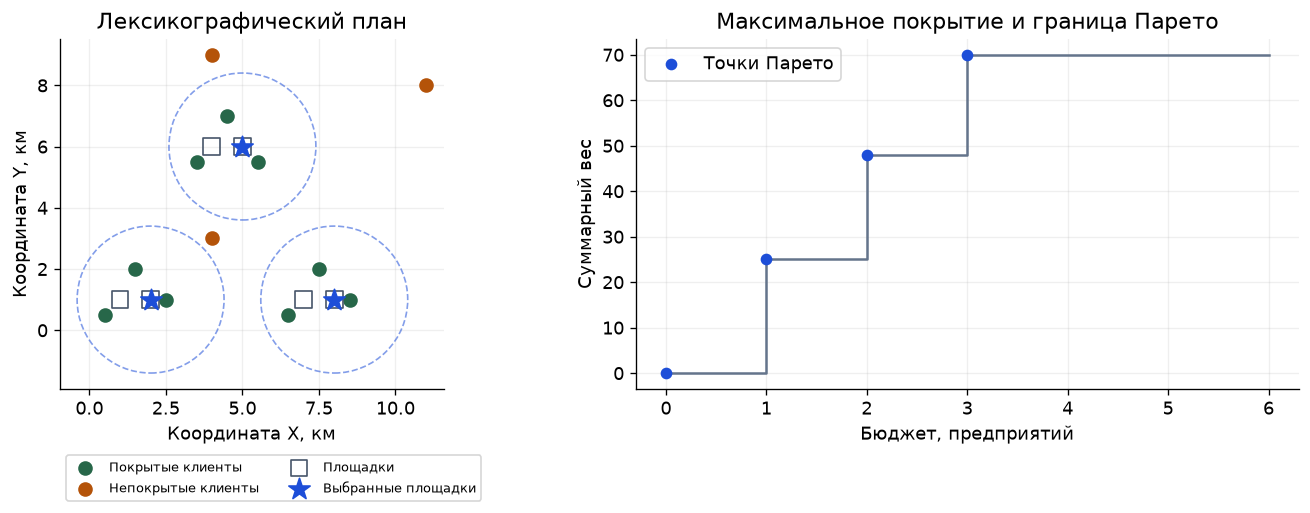

In [4]:
lexicographic_rows_31 = []
for formulation_31, name_31 in model_names_31.items():
    lex_model_31 = build_cover_model_31(coverage_31, weights_31, budget_31, formulation_31, exact=False)
    solve_model(lex_model_31)
    best_weight_31 = int(round(pyo.value(lex_model_31.weight)))
    lex_model_31.keep_coverage = pyo.Constraint(expr=lex_model_31.weight == best_weight_31)
    lex_model_31.objective.deactivate()
    lex_model_31.minimum_sites = pyo.Objective(expr=sum(lex_model_31.open[j] for j in lex_model_31.sites))
    solve_model(lex_model_31)
    lex_sites_31 = [j for j in lex_model_31.sites if pyo.value(lex_model_31.open[j]) > 0.5]
    lexicographic_rows_31.append({
        "Модель": name_31, "Вес покрытия": best_weight_31,
        "Предприятий": len(lex_sites_31), "Площадки": str([j + 1 for j in lex_sites_31])
    })
display(pd.DataFrame(lexicographic_rows_31).set_index("Модель"))

frontier_rows_31 = []
previous_weight_31 = -1
for limit_31 in range(len(site_points_31) + 1):
    frontier_model_31 = build_cover_model_31(coverage_31, weights_31, limit_31, "compact", exact=False)
    solve_model(frontier_model_31)
    weight_31 = int(round(pyo.value(frontier_model_31.weight)))
    frontier_rows_31.append({
        "Бюджет": limit_31, "Максимальный вес": weight_31,
        "Доля веса, %": 100 * weight_31 / weights_31.sum(),
        "Парето": weight_31 > previous_weight_31
    })
    previous_weight_31 = weight_31
frontier_table_31 = pd.DataFrame(frontier_rows_31)
display(frontier_table_31.round(2).set_index("Бюджет"))
assert frontier_table_31["Максимальный вес"].tolist() == [0, 25, 48, 70, 70, 70, 70]

figure_31, axes_31 = plt.subplots(1, 2, figsize=(12, 4.5))
selected_coverage_31 = coverage_31[:, lex_sites_31].any(axis=1)
axes_31[0].scatter(client_points_31[selected_coverage_31, 0], client_points_31[selected_coverage_31, 1],
                   s=60, label="Покрытые клиенты", color="#276749")
axes_31[0].scatter(client_points_31[~selected_coverage_31, 0], client_points_31[~selected_coverage_31, 1],
                   s=60, label="Непокрытые клиенты", color="#b45309")
axes_31[0].scatter(site_points_31[:, 0], site_points_31[:, 1], marker="s", facecolors="none",
                   edgecolors="#475569", s=100, label="Площадки")
axes_31[0].scatter(site_points_31[lex_sites_31, 0], site_points_31[lex_sites_31, 1], marker="*",
                   s=180, color="#1d4ed8", label="Выбранные площадки")
for site_index_31 in lex_sites_31:
    axes_31[0].add_patch(plt.Circle(site_points_31[site_index_31], radius_31, fill=False,
                                  linestyle="--", color="#1d4ed8", alpha=0.55))
axes_31[0].set(xlabel="Координата X, км", ylabel="Координата Y, км", title="Лексикографический план")
axes_31[0].set_aspect("equal")
axes_31[0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.17), ncol=2)
axes_31[1].step(frontier_table_31["Бюджет"], frontier_table_31["Максимальный вес"], where="post", color="#64748b")
efficient_31 = frontier_table_31[frontier_table_31["Парето"]]
axes_31[1].scatter(efficient_31["Бюджет"], efficient_31["Максимальный вес"], color="#1d4ed8", label="Точки Парето", zorder=3)
axes_31[1].set(xlabel="Бюджет, предприятий", ylabel="Суммарный вес", title="Максимальное покрытие и граница Парето")
axes_31[1].set_xticks(range(7))
axes_31[1].legend()
figure_31.tight_layout()
plt.show()

### Ответ

**(a)** Агрегированная модель использует $\sum_i y_{ij}\le |I|x_j$, дезагрегированная — $y_{ij}\le x_j$. Обе дают для примера максимальный вес **70** при четырёх построенных предприятиях.

**(b)** Одноиндексная модель с $z_i\le\sum_{j\in N_i}x_j$ даёт то же покрытие. Для тестов 30/10, 60/20, 120/40 все три целочисленные модели дают соответственно **101, 411, 1293**. LP-оценки агрегированной модели равны **282, 588, 1358**, а у двух остальных — **101, 411, 1293**. Одноиндексная модель устраняет переменные назначений и содержит меньше переменных; дезагрегация усиливает LP-оценку относительно агрегирования. Конкретные размеры и времена приведены в таблице. По одному экземпляру каждого размера нельзя устанавливать универсальный порядок моделей по времени решения.

**(c)** Замена равенства бюджета на неравенство и два последовательных этапа дают покрытие **70 из 89**, или **78,65%**, при **трёх** предприятиях вместо четырёх. Достаточно выбрать по одной площадке из пар $(1,2)$, $(3,4)$, $(5,6)$. Клиенты 10–12 недоступны даже при строительстве всех предприятий.

**(d)** Граница Парето состоит из пар «число предприятий; вес покрытия»:
$$\boxed{(0;0),\ (1;25),\ (2;48),\ (3;70).}$$
Бюджеты 4–6 сохраняют вес 70 и не образуют новых недоминируемых точек.

## Задача 3.2

### Условие

Цель игры Судоку состоит в том, чтобы заполнить сетку $9\times9$ цифрами так, чтобы каждый столбец, каждая строка и каждый из девяти подквадратов $3\times3$, составляющих сетку, содержали все цифры от 1 до 9. Каждая цифра в строке, столбце или подквадрате должна быть уникальной и не может повторяться. Пример пазла Судоку показан ниже:

$$\begin{array}{ccc|ccc|ccc}
 &7& & &2& &4&8& \\
2& &6& & & & & &5\\
 & & & &9& & & & \\\hline
 & & &1&5& & & & \\
 &2& & & & & &6& \\
 & & & &6&7& & & \\\hline
 & & & & &6& & &3\\
6& & &5& & &1& &4\\
 &9&3& &4& & & &7
\end{array}$$

(a) Сформулируйте головоломку Судоку как модель целочисленного оптимизационного программирования. Сформулируйте задачу как модель целочисленной оптимизации, используя указанные выше обозначения. Какова целевая функция? Как мы можем включить в модель фиксированные/заданные элементы Судоку?

(b) Ваша модель даст вам решение, если оно существует, для каждого набора заданных элементов. Судоку называется корректным (proper), если оно имеет ровно одно выполнимое решение. Как вы можете установить, является ли найденное вами решение единственно верным?

(c) Решите приведенный пример Судоку, используя вашу формулировку MILO, и убедитесь, что вы получили допустимое решение. Существуют ли несколько допустимых решений?

### Дано

Исходная сетка взята из рисунка на странице 136 PDF. Строки и столбцы нумеруются сверху вниз и слева направо; допустимые цифры $K=\{1,\ldots,9\}$. В массиве Python пустые клетки обозначаются нулём. Сгенерированных данных в этой задаче нет.

### Математическая модель

**(a)** Трёхмерная переменная $x_{rck}\in\{0,1\}$ (`Binary`) равна 1, если в строке $r$, столбце $c$ стоит цифра $k$. Ищется допустимое заполнение, поэтому целевая функция постоянна:

$$\min 0.$$

Ограничения одной цифры в клетке, одного вхождения цифры в строку и столбец:

$$\sum_{k=1}^9x_{rck}=1\quad(r,c=1,\ldots,9),$$
$$\sum_{c=1}^9x_{rck}=1\quad(r,k=1,\ldots,9),\qquad
\sum_{r=1}^9x_{rck}=1\quad(c,k=1,\ldots,9).$$

Для каждого блока $B_{uv}=\{3u+1,3u+2,3u+3\}\times\{3v+1,3v+2,3v+3\}$, $u,v\in\{0,1,2\}$:

$$\sum_{(r,c)\in B_{uv}}x_{rck}=1\quad(k=1,\ldots,9).$$

Для заданной цифры $g_{rc}$ добавляется $x_{rcg_{rc}}=1$.

**(b)** Пусть первое решение содержит цифры $s_{rc}$. Добавим запрет этого заполнения:

$$\sum_{r=1}^9\sum_{c=1}^9x_{rcs_{rc}}\le80.$$

Если новая модель несовместна, решение единственно. Если допустима, найдено другое заполнение. Такой запрет исключает ровно первое решение.

### Найти

(a) MILO-модель, её целевую функцию и способ фиксации заданных цифр. (b) Способ проверки единственности. (c) Допустимое решение исходного примера и наличие других решений.

### Решение

Целевая функция: 0
Единственность: нет, найдены два решения


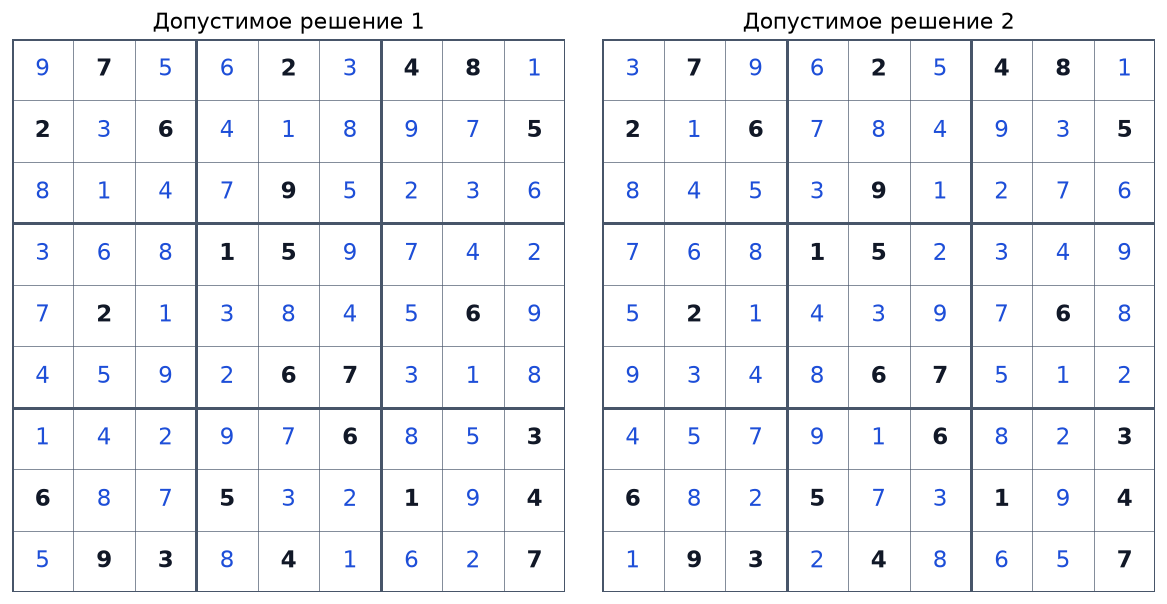

In [5]:
puzzle_32 = np.array([
    [0, 7, 0, 0, 2, 0, 4, 8, 0],
    [2, 0, 6, 0, 0, 0, 0, 0, 5],
    [0, 0, 0, 0, 9, 0, 0, 0, 0],
    [0, 0, 0, 1, 5, 0, 0, 0, 0],
    [0, 2, 0, 0, 0, 0, 0, 6, 0],
    [0, 0, 0, 0, 6, 7, 0, 0, 0],
    [0, 0, 0, 0, 0, 6, 0, 0, 3],
    [6, 0, 0, 5, 0, 0, 1, 0, 4],
    [0, 9, 3, 0, 4, 0, 0, 0, 7]
])
model_32 = pyo.ConcreteModel()
model_32.positions = pyo.RangeSet(0, 8)
model_32.digits = pyo.RangeSet(1, 9)
model_32.value = pyo.Var(model_32.positions, model_32.positions, model_32.digits, domain=pyo.Binary)
model_32.cell = pyo.Constraint(
    model_32.positions, model_32.positions,
    rule=lambda m, r, c: sum(m.value[r, c, k] for k in m.digits) == 1
)
model_32.row = pyo.Constraint(
    model_32.positions, model_32.digits,
    rule=lambda m, r, k: sum(m.value[r, c, k] for c in m.positions) == 1
)
model_32.column = pyo.Constraint(
    model_32.positions, model_32.digits,
    rule=lambda m, c, k: sum(m.value[r, c, k] for r in m.positions) == 1
)
model_32.block = pyo.ConstraintList()
for row_start_32 in range(0, 9, 3):
    for column_start_32 in range(0, 9, 3):
        for digit_32 in model_32.digits:
            model_32.block.add(sum(
                model_32.value[row_32, column_32, digit_32]
                for row_32 in range(row_start_32, row_start_32 + 3)
                for column_32 in range(column_start_32, column_start_32 + 3)
            ) == 1)
for row_32, column_32 in zip(*np.nonzero(puzzle_32)):
    model_32.value[int(row_32), int(column_32), int(puzzle_32[row_32, column_32])].fix(1)
model_32.feasibility = pyo.Objective(expr=0)
solve_model(model_32)

def extract_sudoku_32(model):
    return np.array([
        [next(k for k in model.digits if pyo.value(model.value[r, c, k]) > 0.5) for c in model.positions]
        for r in model.positions
    ])

def validate_sudoku_32(board):
    digits = set(range(1, 10))
    assert all(set(row) == digits for row in board)
    assert all(set(column) == digits for column in board.T)
    assert all(set(board[r:r + 3, c:c + 3].ravel()) == digits
               for r in range(0, 9, 3) for c in range(0, 9, 3))
    assert np.all(board[puzzle_32 != 0] == puzzle_32[puzzle_32 != 0])

first_solution_32 = extract_sudoku_32(model_32)
validate_sudoku_32(first_solution_32)
alternative_32 = model_32.clone()
alternative_32.exclude_first = pyo.Constraint(expr=sum(
    alternative_32.value[r, c, int(first_solution_32[r, c])]
    for r in alternative_32.positions for c in alternative_32.positions
) <= 80)
alternative_solver_32 = make_solver()
alternative_result_32 = alternative_solver_32.solve(alternative_32, load_solutions=False)
alternative_status_32 = alternative_result_32.solver.termination_condition
assert alternative_status_32 in {pyo.TerminationCondition.optimal, pyo.TerminationCondition.infeasible}
solutions_32 = [first_solution_32]
if alternative_status_32 == pyo.TerminationCondition.optimal:
    alternative_32.solutions.load_from(alternative_result_32)
    second_solution_32 = extract_sudoku_32(alternative_32)
    validate_sudoku_32(second_solution_32)
    assert np.any(first_solution_32 != second_solution_32)
    solutions_32.append(second_solution_32)
print(f"Целевая функция: {pyo.value(model_32.feasibility):.0f}")
print("Единственность:", "нет, найдены два решения" if len(solutions_32) == 2 else "да")
figure_32, axes_32 = plt.subplots(1, len(solutions_32), figsize=(5 * len(solutions_32), 5), squeeze=False)
for solution_index_32, board_32 in enumerate(solutions_32):
    axis_32 = axes_32[0, solution_index_32]
    for line_32 in range(10):
        width_32 = 1.8 if line_32 % 3 == 0 else 0.4
        axis_32.plot([0, 9], [line_32, line_32], color="#475569", linewidth=width_32)
        axis_32.plot([line_32, line_32], [0, 9], color="#475569", linewidth=width_32)
    for row_32 in range(9):
        for column_32 in range(9):
            axis_32.text(column_32 + 0.5, 8.5 - row_32, str(board_32[row_32, column_32]),
                         ha="center", va="center", fontsize=14,
                         color="#111827" if puzzle_32[row_32, column_32] else "#1d4ed8",
                         fontweight="bold" if puzzle_32[row_32, column_32] else "normal")
    axis_32.set(xlim=(0, 9), ylim=(0, 9), title=f"Допустимое решение {solution_index_32 + 1}")
    axis_32.set_aspect("equal")
    axis_32.axis("off")
figure_32.tight_layout()
plt.show()

### Ответ

**(a)** Используются 729 бинарных переменных $x_{rck}$ и ограничения уникальности цифры в клетке, строке, столбце и блоке. Целевая функция равна нулю; исходные цифры задаются фиксацией соответствующих переменных в 1.

**(b)** Единственность проверяется повторным решением после добавления $\sum_{r,c}x_{rcs_{rc}}\le80$. Несовместность повторной модели означала бы единственность.

**(c)** На рисунке получены два разных допустимых заполнения исходной сетки. Проверки всех строк, столбцов, блоков и заданных цифр выполнены. Следовательно, исходное судоку **имеет несколько решений** и не является корректным (proper) в смысле условия.

## Задача 3.3

### Условие

Компания имеет $N$ проектов на рассмотрении. Прибыль от проекта $i$, добавленного в течение следующих двух лет, задается как $p_i$. Проект $i$ потребует затрат $c_i$ в течение 1 года и $d_i$ в течение 2 года. В течение 1 года доступны средства $SB_1$, а в течение 2 года — средства $SB_2$. Невозможно выполнить лишь часть каждого проекта. Более того, если выбран проект 4, то проект 5 выбирать не следует. Если выбран проект 7, то проект 8 также должен быть выбран. Наконец, проект 3 должен быть выбран, если выбраны оба проекта 1 и 2, и может не выбираться, если один из проектов 1 или 2 не выбран. Сформулируйте модель целочисленной линейной оптимизации для максимизации прибыли.

### Дано

В источнике численные значения отсутствуют. Для демонстрации выбраны восемь проектов; прибыль, затраты и бюджеты выражены в млн руб. Бюджеты: $B_1=60$, $B_2=50$. Обозначения $SB_1$, $SB_2$ в условии передают денежные суммы; в модели используются $B_1,B_2$.

| Проект $i$ | Прибыль $p_i$ | Затраты первого года $c_i$ | Затраты второго года $d_i$ |
|---:|---:|---:|---:|
| 1 | 28 | 16 | 12 |
| 2 | 24 | 12 | 15 |
| 3 | 18 | 8 | 9 |
| 4 | 32 | 20 | 14 |
| 5 | 29 | 17 | 18 |
| 6 | 15 | 9 | 7 |
| 7 | 38 | 22 | 20 |
| 8 | 20 | 10 | 11 |

### Математическая модель

$x_i\in\{0,1\}$ (`Binary`) равно 1 при выборе проекта $i$. Частичный выбор запрещён бинарностью.

$$\max\sum_{i=1}^N p_i x_i,$$
$$\sum_{i=1}^N c_i x_i\le B_1,\qquad
\sum_{i=1}^N d_i x_i\le B_2,$$
$$x_4+x_5\le1,\qquad x_7\le x_8,\qquad
x_1+x_2-1\le x_3.$$

Последнее ограничение реализует импликацию $(x_1=1\land x_2=1)\Rightarrow x_3=1$. Если оба первых проекта не выбраны одновременно, проект 3 остаётся свободным: условие не запрещает выбрать его отдельно.

### Найти

Модель целочисленной линейной оптимизации, максимизирующую прибыль компании.

### Решение

In [6]:
projects_33 = pd.DataFrame({
    "Прибыль": [28, 24, 18, 32, 29, 15, 38, 20],
    "Год 1": [16, 12, 8, 20, 17, 9, 22, 10],
    "Год 2": [12, 15, 9, 14, 18, 7, 20, 11]
}, index=range(1, 9))
projects_33.index.name = "Проект"
budgets_33 = [60, 50]
model_33 = pyo.ConcreteModel()
model_33.projects = pyo.RangeSet(1, 8)
model_33.selected = pyo.Var(model_33.projects, domain=pyo.Binary)
model_33.profit = pyo.Objective(
    expr=sum(int(projects_33.loc[i, "Прибыль"]) * model_33.selected[i] for i in model_33.projects),
    sense=pyo.maximize
)
model_33.year_one = pyo.Constraint(expr=sum(
    int(projects_33.loc[i, "Год 1"]) * model_33.selected[i] for i in model_33.projects
) <= budgets_33[0])
model_33.year_two = pyo.Constraint(expr=sum(
    int(projects_33.loc[i, "Год 2"]) * model_33.selected[i] for i in model_33.projects
) <= budgets_33[1])
model_33.exclusion = pyo.Constraint(expr=model_33.selected[4] + model_33.selected[5] <= 1)
model_33.dependency = pyo.Constraint(expr=model_33.selected[7] <= model_33.selected[8])
model_33.joint_dependency = pyo.Constraint(expr=model_33.selected[1] + model_33.selected[2] - 1 <= model_33.selected[3])
solve_model(model_33)
selection_33 = np.array([int(round(pyo.value(model_33.selected[i]))) for i in model_33.projects])
result_33 = projects_33.copy()
result_33.insert(0, "Выбран", selection_33)
display(result_33)
spent_33 = projects_33[["Год 1", "Год 2"]].to_numpy().T @ selection_33
display(pd.DataFrame({"Расход": spent_33, "Бюджет": budgets_33, "Остаток": np.array(budgets_33) - spent_33},
                     index=["Год 1", "Год 2"]))
assert np.all(spent_33 <= budgets_33)
assert selection_33[3] + selection_33[4] <= 1
assert selection_33[6] <= selection_33[7]
assert selection_33[0] + selection_33[1] - 1 <= selection_33[2]
assert np.isclose(pyo.value(model_33.profit), 102)
print(f"Максимальная прибыль: {pyo.value(model_33.profit):.0f} млн руб.")

,Выбран,Прибыль,Год 1,Год 2
Проект,,,,
1,1,28,16,12
2,1,24,12,15
3,1,18,8,9
4,1,32,20,14
5,0,29,17,18
6,0,15,9,7
7,0,38,22,20
8,0,20,10,11


,Расход,Бюджет,Остаток
Год 1,56,60,4
Год 2,50,50,0


Максимальная прибыль: 102 млн руб.


### Ответ

Искомая модель: бинарный выбор проектов, максимизация $\sum_i p_ix_i$, два бюджетных ограничения и логические связи $x_4+x_5\le1$, $x_7\le x_8$, $x_1+x_2-1\le x_3$. На учебных данных модель выбирает проекты **1, 2, 3, 4** и даёт прибыль **102 млн руб.**

## Задача 3.4

### Условие

Производитель может производить $n$ различных продуктов и продавать продукт $i$ с прибылью $Sp_i$ $(i=1,\ldots,n)$. Более того, для производства 1 единицы...

продукта $i$. Всего доступно $R$ единиц сырья. Если какой-либо продукт $i$ производится, возникают фиксированные затраты на наладку оборудования (setup cost) в размере $Sc_i$. Производитель может продать не более $M_i$ единиц продукта $i$. Сформулируйте модель целочисленной оптимизации для максимизации прибыли.

### Дано

В исходном PDF предложение о расходе сырья обрывается после слов «для производства 1 единицы...». Пропуск сохранён в условии. Для построения модели обозначим через $a_i$ расход сырья на единицу продукта; это явное дополнение к неполному фрагменту. Обозначения $p_i$ и $c_i$ далее означают денежные величины прибыли и затрат на наладку.

Численные параметры ниже выбраны для демонстрации модели; в методичке их нет. Продукция в примере выпускается целыми единицами. Все денежные величины заданы в условных денежных единицах, запас сырья $R=180$.

| Продукт $i$ | Прибыль $p_i$ | Расход сырья $a_i$ | Наладка $c_i$ | Предел продаж $M_i$ |
|---:|---:|---:|---:|---:|
| 1 | 28 | 2 | 80 | 40 |
| 2 | 42 | 3 | 130 | 30 |
| 3 | 35 | 2 | 100 | 35 |
| 4 | 55 | 4 | 160 | 20 |

### Математическая модель

$x_i\in\mathbb Z_{\ge0}$ (`NonNegativeIntegers`) — объём выпуска; $z_i\in\{0,1\}$ (`Binary`) — признак производства продукта. Допустимая верхняя граница
$U_i=\min\{M_i,\lfloor R/a_i\rfloor\}$ служит индивидуальной константой big-M; в примере $U=(40,30,35,20)$.

$$
\max\ \sum_{i=1}^{n}(p_ix_i-c_iz_i)
$$
$$
\sum_{i=1}^{n}a_ix_i\le R,\qquad
z_i\le x_i\le U_i z_i\quad(i=1,\ldots,n),
$$
$$
x_i\in\mathbb Z_{\ge0},\qquad z_i\in\{0,1\}.
$$

При $z_i=0$ выпуск равен нулю; при положительном выпуске $z_i=1$ и затраты на наладку учитываются один раз. Нижняя связь $x_i\ge z_i$ выражает выпуск хотя бы одной целой единицы при включении продукта. Это линеаризация фиксированных затрат из § 3.2.3 главы.

### Найти

Сформулировать модель целочисленной оптимизации для максимизации прибыли производителя.

### Решение

In [7]:
product_data_34 = pd.DataFrame({
    "profit": [28, 42, 35, 55],
    "material": [2, 3, 2, 4],
    "setup": [80, 130, 100, 160],
    "sales_limit": [40, 30, 35, 20],
}, index=pd.Index(range(1, 5), name="Продукт"))
material_budget_34 = 180
upper_bounds_34 = {
    product: min(int(row.sales_limit), material_budget_34 // int(row.material))
    for product, row in product_data_34.iterrows()
}

production_34 = pyo.ConcreteModel()
production_34.products = pyo.Set(initialize=product_data_34.index.tolist())
production_34.quantity = pyo.Var(production_34.products, domain=pyo.NonNegativeIntegers)
production_34.enabled = pyo.Var(production_34.products, domain=pyo.Binary)
production_34.material_limit = pyo.Constraint(
    expr=sum(product_data_34.loc[product, "material"] * production_34.quantity[product]
             for product in production_34.products) <= material_budget_34
)
production_34.activation_upper = pyo.Constraint(
    production_34.products,
    rule=lambda model, product: model.quantity[product]
    <= upper_bounds_34[product] * model.enabled[product],
)
production_34.activation_lower = pyo.Constraint(
    production_34.products,
    rule=lambda model, product: model.quantity[product] >= model.enabled[product],
)
production_34.profit = pyo.Objective(
    expr=sum(product_data_34.loc[product, "profit"] * production_34.quantity[product]
             - product_data_34.loc[product, "setup"] * production_34.enabled[product]
             for product in production_34.products),
    sense=pyo.maximize,
)
result_34 = solve_model(production_34)

quantities_34 = np.array([
    int(round(pyo.value(production_34.quantity[product])))
    for product in production_34.products
])
active_34 = np.array([
    int(round(pyo.value(production_34.enabled[product])))
    for product in production_34.products
])
result_table_34 = pd.DataFrame({
    "Выпуск": quantities_34,
    "Наладка включена": active_34,
    "Расход сырья": product_data_34.material.to_numpy() * quantities_34,
    "Прибыль после наладки": product_data_34.profit.to_numpy() * quantities_34
    - product_data_34.setup.to_numpy() * active_34,
}, index=product_data_34.index)
assert np.array_equal(active_34, (quantities_34 > 0).astype(int))
assert result_table_34["Расход сырья"].sum() <= material_budget_34
assert np.all(quantities_34 <= product_data_34.sales_limit.to_numpy())
display(result_table_34)
print(f"Прибыль: {pyo.value(production_34.profit):.0f}")
print(f"Использовано сырья: {result_table_34['Расход сырья'].sum()} из {material_budget_34}")

,Выпуск,Наладка включена,Расход сырья,Прибыль после наладки
Продукт,,,,
1,40,1,80,1040
2,10,1,30,290
3,35,1,70,1125
4,0,0,0,0


Прибыль: 2455
Использовано сырья: 180 из 180


### Ответ

Искомая модель максимизирует $\sum_i(p_ix_i-c_iz_i)$ при ограничении на сырьё и связях $z_i\le x_i\le U_i z_i$, где $x_i$ целые неотрицательные, $z_i$ бинарные. Тем самым фиксированные затраты учитываются только для выпускаемых продуктов.

В учебном примере оптимально выпустить $(40,10,35,0)$ единиц продуктов; максимальная прибыль равна **2455** денежных единиц, расход сырья — 180 из 180.

## Задача 3.5

### Условие

Крупный город разделен на $d$ районов. Время (в минутах), необходимое машине скорой помощи для поездки из района $i$ в район $j$, задается величиной $t_{ij}$. Время в пути внутри района незначительно, поэтому мы предполагаем $t_{ii}=0$. Население района $i$ составляет $p_i$. Город располагает $n$ машинами скорой помощи и хочет разместить их так, чтобы максимизировать количество людей, живущих в пределах $\alpha$ минут от машины скорой помощи. Поскольку в районе 1 есть больница, в районе 1 обязательно должна быть размещена хотя бы одна машина скорой помощи. Затраты на размещение машины скорой помощи в районе $i$ составляют $Sc_i$ в год. Доступный годовой бюджет составляет $\$C$ в год. Сформулируйте модель целочисленной (линейной) оптимизации для достижения указанной выше цели.

### Дано

Учебный пример выбран для демонстрации работы модели: $d=6$ районов, $n=2$ машины, норматив $\alpha=8$ минут, годовой бюджет $C=135$ тыс. денежных единиц. Стоимость $c_i$ относится к **одной** машине в районе.

| Район $i$ | Население $p_i$, тыс. человек | Стоимость $c_i$, тыс. ден. ед./год |
|---:|---:|---:|
| 1 | 12 | 50 |
| 2 | 18 | 65 |
| 3 | 30 | 70 |
| 4 | 20 | 90 |
| 5 | 16 | 80 |
| 6 | 9 | 55 |

Матрица $T=(t_{ij})$ времени в пути в минутах:

$$
T=\begin{pmatrix}
0&7&14&21&28&35\\
7&0&7&14&21&28\\
14&7&0&7&14&21\\
21&14&7&0&7&14\\
28&21&14&7&0&7\\
35&28&21&14&7&0
\end{pmatrix}.
$$

Числа отсутствуют в исходной постановке и заданы только для проверочного расчёта.

### Математическая модель

$x_i\in\mathbb Z_{\ge0}$ (`NonNegativeIntegers`) — количество машин в районе $i$; $y_j\in\{0,1\}$ (`Binary`) — признак покрытия населения района $j$. Обозначим $N_j=\{i:t_{ij}\le\alpha\}$ — районы, из которых можно прибыть в район $j$ за нормативное время.

$$
\max\ \sum_{j=1}^{d}p_jy_j
$$
$$
\sum_{i=1}^{d}x_i=n,\qquad x_1\ge1,\qquad
\sum_{i=1}^{d}c_ix_i\le C,
$$
$$
y_j\le\sum_{i\in N_j}x_i\le n y_j\quad(j=1,\ldots,d),
\qquad x_i\in\mathbb Z_{\ge0},\quad y_j\in\{0,1\}.
$$

Две связи обеспечивают $y_j=1$ тогда и только тогда, когда хотя бы одна машина находится в допустимой близости. Несколько машин разрешено разместить в одном районе, но его население учитывается в цели один раз. Верхняя граница $n$ следует из общего размера автопарка.

### Найти

Сформулировать целочисленную линейную модель размещения машин, максимизирующую население в пределах $\alpha$ минут от скорой помощи.

### Решение

In [8]:
population_35 = np.array([12, 18, 30, 20, 16, 9])
location_cost_35 = np.array([50, 65, 70, 90, 80, 55])
travel_time_35 = np.array([
    [0, 7, 14, 21, 28, 35],
    [7, 0, 7, 14, 21, 28],
    [14, 7, 0, 7, 14, 21],
    [21, 14, 7, 0, 7, 14],
    [28, 21, 14, 7, 0, 7],
    [35, 28, 21, 14, 7, 0],
])
fleet_size_35 = 2
time_limit_35 = 8
budget_35 = 135
neighbors_35 = {
    district: [origin for origin in range(1, 7)
               if travel_time_35[origin - 1, district - 1] <= time_limit_35]
    for district in range(1, 7)
}

ambulance_35 = pyo.ConcreteModel()
ambulance_35.districts = pyo.RangeSet(1, 6)
ambulance_35.vehicles = pyo.Var(
    ambulance_35.districts, domain=pyo.NonNegativeIntegers, bounds=(0, fleet_size_35)
)
ambulance_35.covered = pyo.Var(ambulance_35.districts, domain=pyo.Binary)
ambulance_35.fleet = pyo.Constraint(
    expr=sum(ambulance_35.vehicles[district] for district in ambulance_35.districts)
    == fleet_size_35
)
ambulance_35.hospital = pyo.Constraint(expr=ambulance_35.vehicles[1] >= 1)
ambulance_35.budget = pyo.Constraint(
    expr=sum(location_cost_35[district - 1] * ambulance_35.vehicles[district]
             for district in ambulance_35.districts) <= budget_35
)
ambulance_35.coverage_lower = pyo.Constraint(
    ambulance_35.districts,
    rule=lambda model, district: model.covered[district]
    <= sum(model.vehicles[origin] for origin in neighbors_35[district]),
)
ambulance_35.coverage_upper = pyo.Constraint(
    ambulance_35.districts,
    rule=lambda model, district: sum(model.vehicles[origin] for origin in neighbors_35[district])
    <= fleet_size_35 * model.covered[district],
)
ambulance_35.population = pyo.Objective(
    expr=sum(population_35[district - 1] * ambulance_35.covered[district]
             for district in ambulance_35.districts),
    sense=pyo.maximize,
)
result_35 = solve_model(ambulance_35)

vehicles_35 = np.array([
    int(round(pyo.value(ambulance_35.vehicles[district])))
    for district in ambulance_35.districts
])
covered_35 = np.array([
    int(round(pyo.value(ambulance_35.covered[district])))
    for district in ambulance_35.districts
])
actual_coverage_35 = ((travel_time_35 <= time_limit_35).T @ vehicles_35 > 0).astype(int)
assert np.array_equal(covered_35, actual_coverage_35)
assert vehicles_35.sum() == fleet_size_35 and vehicles_35[0] >= 1
assert location_cost_35 @ vehicles_35 <= budget_35
display(pd.DataFrame({
    "Машин": vehicles_35,
    "Район покрыт": covered_35,
    "Покрыто, тыс. человек": population_35 * covered_35,
    "Затраты, тыс. ден. ед.": location_cost_35 * vehicles_35,
}, index=pd.Index(range(1, 7), name="Район")))
print(f"Покрыто: {population_35 @ covered_35} из {population_35.sum()} тыс. человек")
print(f"Годовые затраты: {location_cost_35 @ vehicles_35} из {budget_35} тыс. ден. ед.")

,Машин,Район покрыт,"Покрыто, тыс. человек","Затраты, тыс. ден. ед."
Район,,,,
1,1,1,12,50
2,0,1,18,0
3,1,1,30,70
4,0,1,20,0
5,0,0,0,0
6,0,0,0,0


Покрыто: 80 из 105 тыс. человек
Годовые затраты: 120 из 135 тыс. ден. ед.


### Ответ

Искомая модель максимизирует $\sum_jp_jy_j$, размещает ровно $n$ целых машин, требует $x_1\ge1$, соблюдает бюджет и связывает $y_j$ с наличием машины в множестве $N_j$.

Для учебных данных оптимально разместить по одной машине в районах 1 и 3. Покрыты районы 1–4: **80 тыс. человек** из 105 тыс.; годовые затраты равны 120 тыс. денежных единиц.

## Задача 3.6

### Условие

В данном округе имеется $n$ городов. Округ должен определить, где построить пожарные депо. Округ хочет построить минимальное количество пожарных депо, необходимое для того, чтобы гарантировать, что по крайней быть одно пожарное депо находится в пределах 15 минут (времени в пути) от каждого города. Время (в минутах), необходимое для поездки между городами округа, предварительно вычислено и задано в виде таблицы. Сформулируйте модель целочисленного линейного программирования, которая определит, сколько пожарных депо необходимо построить и где они должны быть расположены.

### Дано

Порог прибытия **15 минут** взят из условия. Остальные числа заданы для демонстрации: $n=9$ городов на одной дороге; их положения в минутах движения от начала дороги равны
$r=(0,8,16,45,53,61,90,98,106)$. Время в пути задаётся формулой $t_{ij}=|r_i-r_j|$, поэтому матрица симметрична и $t_{ii}=0$.

$$
T=\begin{pmatrix}
0&8&16&45&53&61&90&98&106\\
8&0&8&37&45&53&82&90&98\\
16&8&0&29&37&45&74&82&90\\
45&37&29&0&8&16&45&53&61\\
53&45&37&8&0&8&37&45&53\\
61&53&45&16&8&0&29&37&45\\
90&82&74&45&37&29&0&8&16\\
98&90&82&53&45&37&8&0&8\\
106&98&90&61&53&45&16&8&0
\end{pmatrix}.
$$

### Математическая модель

$z_i\in\{0,1\}$ (`Binary`) — решение построить депо в городе $i$. Для каждого города $j$ определим $N_j=\{i:t_{ij}\le15\}$.

$$
\min\ \sum_{i=1}^{n}z_i
$$
$$
\sum_{i\in N_j}z_i\ge1\quad(j=1,\ldots,n),\qquad
z_i\in\{0,1\}.
$$

Это задача покрытия множества: каждый город должен быть покрыт хотя бы одним депо. Дополнительные депо в том же городе не расширяют покрытие, поэтому бинарной переменной достаточно.

### Найти

Сформулировать целочисленную линейную модель, определяющую минимальное количество пожарных депо и города их размещения.

### Решение

In [9]:
positions_36 = np.array([0, 8, 16, 45, 53, 61, 90, 98, 106])
travel_time_36 = np.abs(positions_36[:, None] - positions_36[None, :])
response_limit_36 = 15
neighbors_36 = {
    city: [origin for origin in range(1, 10)
           if travel_time_36[origin - 1, city - 1] <= response_limit_36]
    for city in range(1, 10)
}

fire_stations_36 = pyo.ConcreteModel()
fire_stations_36.cities = pyo.RangeSet(1, 9)
fire_stations_36.build = pyo.Var(fire_stations_36.cities, domain=pyo.Binary)
fire_stations_36.coverage = pyo.Constraint(
    fire_stations_36.cities,
    rule=lambda model, city: sum(model.build[origin] for origin in neighbors_36[city]) >= 1,
)
fire_stations_36.station_count = pyo.Objective(
    expr=sum(fire_stations_36.build[city] for city in fire_stations_36.cities),
    sense=pyo.minimize,
)
result_36 = solve_model(fire_stations_36)

built_36 = np.array([
    int(round(pyo.value(fire_stations_36.build[city])))
    for city in fire_stations_36.cities
])
selected_cities_36 = np.flatnonzero(built_36) + 1
nearest_time_36 = travel_time_36[built_36 == 1, :].min(axis=0)
assert np.all(nearest_time_36 <= response_limit_36)
display(pd.DataFrame({
    "Депо построено": built_36,
    "Время от ближайшего депо, мин": nearest_time_36,
}, index=pd.Index(range(1, 10), name="Город")))
print(f"Минимальное число депо: {built_36.sum()}")
print("Города размещения:", ", ".join(map(str, selected_cities_36)))

,Депо построено,"Время от ближайшего депо, мин"
Город,,
1,0,8
2,1,0
3,0,8
4,0,8
5,1,0
6,0,8
7,0,8
8,1,0
9,0,8


Минимальное число депо: 3
Города размещения: 2, 5, 8


### Ответ

Искомая модель: $\min\sum_i z_i$ при $\sum_{i:t_{ij}\le15}z_i\ge1$ для каждого города $j$ и бинарных $z_i$.

В учебном примере необходимы **3 депо**, в городах **2, 5 и 8**. Время прибытия в любой город не превышает 8 минут. Меньше трёх депо недостаточно, поскольку три группы городов отделены друг от друга временем пути более 15 минут.

## Задача 3.7

### Условие

В закусочной со средним темпом обслуживания подготовка блюд предшествует приходу клиентов из-за всплесков спроса и ограниченной мощности кухни. 8-часовая смена разбита на 48 10-минутных интервалов, с дополнительным часом перед открытием для добавления еще шести интервалов.

В течение каждого интервала может быть начато приготовление до $C$ блюд, готовых к продаже в интервале $t+2$ и остающихся пригодными для продажи до интервала $t+8$, после чего они списываются. В любой момент времени в процессе приготовления может находиться не более $C$ блюд, независимо от времени начала их приготовления.

Учитывая исторический средний спрос $d_t$ для каждого интервала, сформулируйте задачу MILO, чтобы определить количество блюд, приготовление которых необходимо начинать в каждом интервале для удовлетворения этого спроса.

### Дано

Из условия: 48 рабочих интервалов по 10 минут; 6 подготовительных интервалов; длительность приготовления 2 интервала; продажи партии, начатой в $t$, разрешены в интервалах $t+2,\ldots,t+8$ включительно.

Нумеруем подготовительные интервалы $-5,\ldots,0$, рабочие — $1,\ldots,48$. Начального запаса до интервала $-5$ нет. Для воспроизводимого учебного примера выбраны $C=24$ блюда и целочисленный спрос:

| Рабочие интервалы | Спрос по порядку, блюд |
|---|---|
| 1–12 | 6, 6, 7, 8, 8, 9, 10, 10, 12, 14, 16, 18 |
| 13–24 | 18, 18, 16, 14, 12, 10, 8, 8, 7, 7, 8, 8 |
| 25–36 | 9, 9, 10, 12, 14, 16, 18, 18, 16, 14, 12, 10 |
| 37–48 | 8, 8, 7, 7, 6, 6, 5, 5, 4, 4, 3, 3 |

До открытия спрос равен нулю. Значения $C$ и $d_t$ выбраны для демонстрации, а не взяты из методички. Если средний прогноз дробный, при целочисленных продажах требование «не менее прогноза» означает округление спроса вверх; здесь такое округление не требуется.

### Математическая модель

Пусть $T=\{-5,\ldots,48\}$, $H=\{1,\ldots,48\}$, а
$E=\{(t,s):t\in T,\ s\in H,\ t+2\le s\le t+8\}$.

$x_t\in\mathbb Z_{\ge0}$ (`NonNegativeIntegers`) — число блюд, приготовление которых начинается в интервале $t$;
$v_{ts}\in\mathbb Z_{\ge0}$ (`NonNegativeIntegers`) — число блюд этой партии, проданных в интервале $s$; переменные $v_{ts}$ существуют только для $(t,s)\in E$.

$$
0\le x_t\le C,\qquad x_{t-1}+x_t\le C\quad(t\in T),\qquad x_{-6}=0,
$$
$$
\sum_{s:(t,s)\in E}v_{ts}\le x_t\quad(t\in T),\qquad
\sum_{t:(t,s)\in E}v_{ts}=d_s\quad(s\in H).
$$

Первое ограничение мощности учитывает одновременно обе находящиеся в приготовлении партии. Второе не позволяет продать одну порцию дважды. Индексы $E$ запрещают продажу до готовности и после срока годности. Если для партии нет допустимых продаж, сумма по пустому множеству равна нулю.

В исходном упражнении целевая функция не задана: достаточно найти допустимый план, то есть использовать $\min 0$. Для демонстрационного расчёта введём дополнительный критерий
$$
\min\ \sum_{t\in T}x_t,
$$
который среди допустимых планов выбирает план с минимальным количеством приготовленных блюд. Это дополнительное правило выбора плана, позволяющее избежать излишков; все требования исходной постановки остаются обязательными.

### Найти

Сформулировать MILO-модель, определяющую количество блюд, приготовление которых нужно начинать в каждом интервале для удовлетворения спроса.

### Решение

До открытия и первая половина              Вторая половина             
                        Интервал Начато Спрос        Интервал Начато Спрос
0                             -5      0     0              22      7     7
1                             -4     13     0              23     17     8
2                             -3      6     0              24      7     8
3                             -2     17     0              25      9     9
4                             -1      7     0              26     12     9
5                              0     12     0              27     12    10
6                              1      8     6              28     12    12
7                              2     16     6              29     10    14
8                              3      7     7              30     12    16
9                              4     16     8              31     12    18
10                             5      8     8              32     12    18
11                             6     16     9              33     12    16
12                             7      8    10              34      7    14
13                             8     16    10              35     16    12
14                             9      5    12              36      7    10
15                            10     18    14              37     11     8
16                            11      6    16              38      6     8
17                            12      8    18              39      0     7
18                            13      4    18              40      3     7
19                            14     17    18              41     16     6
20                            15      7    16              42      0     6
21                            16     17    14              43      0     5
22                            17      2    12              44      0     5
23                            18     19    10              45      0     4
24                            19      5     8              46      0     4
25                            20     12     8              47      0     3
26                            21     12     7              48      0     3

Приготовлено и продано: 482 блюд
Излишек: 0 блюд
Максимум одновременно в приготовлении: 24 из 24


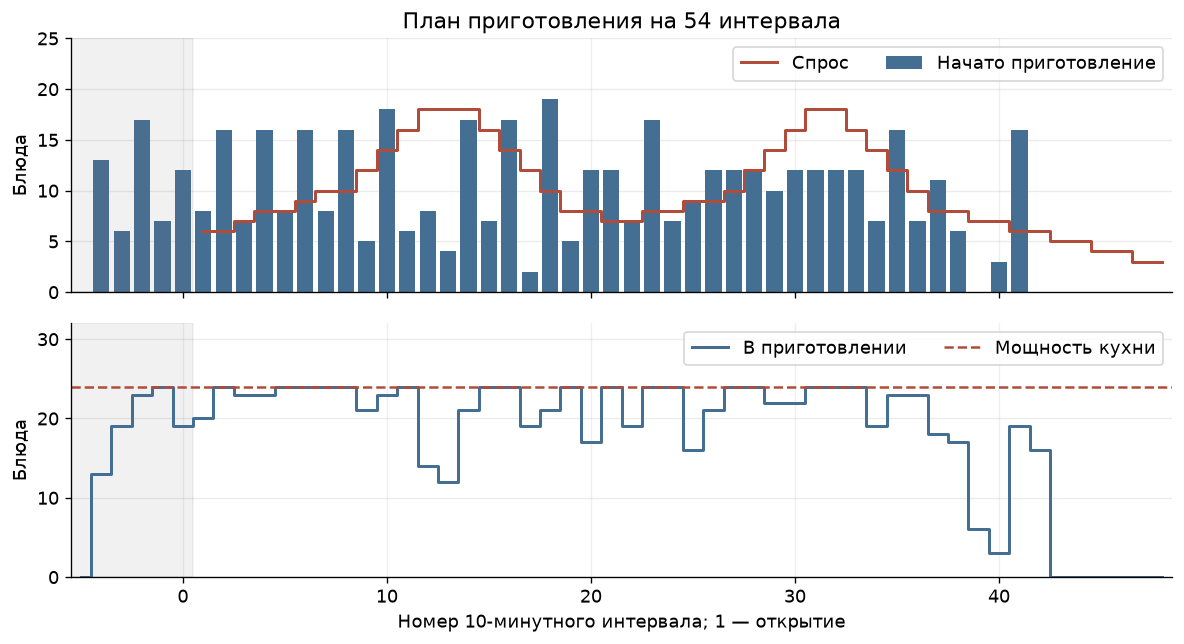

In [10]:
demand_values_37 = np.array([
    6, 6, 7, 8, 8, 9, 10, 10, 12, 14, 16, 18,
    18, 18, 16, 14, 12, 10, 8, 8, 7, 7, 8, 8,
    9, 9, 10, 12, 14, 16, 18, 18, 16, 14, 12, 10,
    8, 8, 7, 7, 6, 6, 5, 5, 4, 4, 3, 3,
])
kitchen_capacity_37 = 24
periods_37 = list(range(-5, 49))
selling_periods_37 = list(range(1, 49))
demand_37 = dict(zip(selling_periods_37, demand_values_37.tolist()))
sale_arcs_37 = [(start, sale) for start in periods_37 for sale in selling_periods_37
                if start + 2 <= sale <= start + 8]

kitchen_37 = pyo.ConcreteModel()
kitchen_37.periods = pyo.Set(initialize=periods_37, ordered=True)
kitchen_37.selling_periods = pyo.Set(initialize=selling_periods_37, ordered=True)
kitchen_37.sale_arcs = pyo.Set(initialize=sale_arcs_37, dimen=2)
kitchen_37.started = pyo.Var(
    kitchen_37.periods, domain=pyo.NonNegativeIntegers, bounds=(0, kitchen_capacity_37)
)
kitchen_37.sold = pyo.Var(kitchen_37.sale_arcs, domain=pyo.NonNegativeIntegers)
kitchen_37.cooking_capacity = pyo.Constraint(
    kitchen_37.periods,
    rule=lambda model, period: model.started[period]
    + (model.started[period - 1] if period > periods_37[0] else 0) <= kitchen_capacity_37,
)
kitchen_37.batch_balance = pyo.Constraint(
    kitchen_37.periods,
    rule=lambda model, start: sum(model.sold[start, sale] for sale in selling_periods_37
                                  if (start, sale) in model.sale_arcs) <= model.started[start],
)
kitchen_37.demand = pyo.Constraint(
    kitchen_37.selling_periods,
    rule=lambda model, sale: sum(model.sold[start, sale] for start in periods_37
                                 if (start, sale) in model.sale_arcs) == demand_37[sale],
)
kitchen_37.total_started = pyo.Objective(
    expr=sum(kitchen_37.started[period] for period in kitchen_37.periods),
    sense=pyo.minimize,
)
result_37 = solve_model(kitchen_37)

started_37 = {period: int(round(pyo.value(kitchen_37.started[period])))
              for period in periods_37}
sold_37 = {(start, sale): int(round(pyo.value(kitchen_37.sold[start, sale])))
           for start, sale in sale_arcs_37}
served_37 = {sale: sum(sold_37[start, sale] for start in periods_37
                       if (start, sale) in sold_37) for sale in selling_periods_37}
batch_used_37 = {start: sum(sold_37[start, sale] for sale in selling_periods_37
                           if (start, sale) in sold_37) for start in periods_37}
in_cooking_37 = np.array([started_37[period] + started_37.get(period - 1, 0)
                          for period in periods_37])
assert all(served_37[sale] == demand_37[sale] for sale in selling_periods_37)
assert all(batch_used_37[start] <= started_37[start] for start in periods_37)
assert in_cooking_37.max() <= kitchen_capacity_37
assert sum(started_37.values()) == sum(demand_37.values())

schedule_37 = pd.DataFrame({
    "Интервал": periods_37,
    "Начато": [started_37[period] for period in periods_37],
    "Спрос": [demand_37.get(period, 0) for period in periods_37],
})
schedule_compact_37 = pd.concat({
    "До открытия и первая половина": schedule_37.iloc[:27].reset_index(drop=True),
    "Вторая половина": schedule_37.iloc[27:].reset_index(drop=True),
}, axis=1)
display(schedule_compact_37)
print(f"Приготовлено и продано: {sum(started_37.values())} блюд")
print(f"Излишек: {sum(started_37.values()) - sum(served_37.values())} блюд")
print(f"Максимум одновременно в приготовлении: {in_cooking_37.max()} из {kitchen_capacity_37}")

figure_37, axes_37 = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axes_37[0].bar(periods_37, [started_37[period] for period in periods_37],
               color="#446E92", label="Начато приготовление")
axes_37[0].step(selling_periods_37, demand_values_37, where="mid",
                color="#B04C39", linewidth=1.8, label="Спрос")
axes_37[0].set_ylabel("Блюда")
axes_37[0].set_ylim(0, max(max(started_37.values()), int(demand_values_37.max())) + 6)
axes_37[0].set_title("План приготовления на 54 интервала")
axes_37[0].legend(loc="upper right", ncol=2)
axes_37[1].step(periods_37, in_cooking_37, where="mid", color="#446E92",
                linewidth=1.8, label="В приготовлении")
axes_37[1].axhline(kitchen_capacity_37, color="#B04C39", linestyle="--",
                   label="Мощность кухни")
axes_37[1].set_ylabel("Блюда")
axes_37[1].set_ylim(0, kitchen_capacity_37 + 8)
axes_37[1].set_xlabel("Номер 10-минутного интервала; 1 — открытие")
axes_37[1].legend(loc="upper right", ncol=2)
for axis_37 in axes_37:
    axis_37.axvspan(-5.5, 0.5, color="#777777", alpha=0.10)
    axis_37.set_xlim(-5.5, 48.5)
    axis_37.grid(axis="y", alpha=0.25)
figure_37.tight_layout()
plt.show()

### Ответ

Искомая MILO-модель использует целочисленные начала приготовления $x_t$ и продажи партий $v_{ts}$. Ограничения $x_{t-1}+x_t\le C$ соблюдают мощность кухни, балансы партий исключают повторную продажу, а множество допустимых пар $(t,s)$ обеспечивает готовность и срок годности. Равенства спроса задают требуемый объём продаж в каждом рабочем интервале.

Для учебного примера допустимый план начала приготовления приведён в таблице: приготовлено и продано **482 блюда**, спрос удовлетворён полностью, излишков нет, одновременно готовится не более 24 блюд.

## Задача 3.8

### Условие

Сформулируйте в виде задачи смешанной целочисленной оптимизации и решите следующую задачу:

$$
\frac{abc}{def}=\frac{1}{5},
$$

где $a$, $b$, $c$, $d$, $e$ и $f$ должны принимать различные целочисленные значения из множества $\{1,2,\ldots,6\}$. Подсказка: $\log(ab)=\log(a)+\log(b)$ и $2x-1$ переводит $\mathbb B$ в $\{-1,1\}$.

### Дано

- Используются все числа $K=\{1,2,3,4,5,6\}$ по одному разу.
- Произведение трёх чисел в числителе должно составлять $1/5$ произведения остальных трёх чисел.
- Дополнительные числовые данные не вводятся.

### Математическая модель

Пусть $z_k\in\{0,1\}$ (`Binary`) равно 1, если число $k$ помещено в числитель, и 0, если оно помещено в знаменатель. Порядок множителей внутри каждой тройки не влияет на результат; после решения располагаем их по возрастанию.

Логарифмирование превращает условие на произведения в линейное равенство с постоянными коэффициентами:

$$
\sum_{k=1}^{6}z_k=3,\qquad
\sum_{k=1}^{6}(2z_k-1)\ln k=-\ln 5,\qquad
z_k\in\{0,1\}.
$$

Требуется найти допустимое решение, поэтому целевая функция постоянна: $\min 0$. Числа $a,b,c$ восстанавливаются из выбранной тройки, а $d,e,f$ — из её дополнения. Полученный результат проверяется точным целочисленным равенством $5abc=def$; это исключает зависимость вывода от погрешности логарифмов.

### Найти

Сформулировать модель MILO и найти различные $a,b,c,d,e,f\in\{1,\ldots,6\}$, удовлетворяющие указанному равенству.

### Решение

In [11]:
numbers_38 = tuple(range(1, 7))
model_38 = pyo.ConcreteModel()
model_38.numbers = pyo.Set(initialize=numbers_38)
model_38.in_numerator = pyo.Var(model_38.numbers, domain=pyo.Binary)
model_38.three_numbers = pyo.Constraint(
    expr=sum(model_38.in_numerator[number] for number in numbers_38) == 3
)
model_38.log_ratio = pyo.Constraint(
    expr=sum(
        (2 * model_38.in_numerator[number] - 1) * float(np.log(number))
        for number in numbers_38
    ) == -float(np.log(5))
)
model_38.feasibility = pyo.Objective(expr=0)
solve_model(model_38)

numerator_numbers_38 = [
    number for number in numbers_38
    if pyo.value(model_38.in_numerator[number]) > 0.5
]
denominator_numbers_38 = [
    number for number in numbers_38
    if pyo.value(model_38.in_numerator[number]) < 0.5
]
numerator_38 = int(np.prod(numerator_numbers_38))
denominator_38 = int(np.prod(denominator_numbers_38))
assert len(numerator_numbers_38) == len(denominator_numbers_38) == 3
assert sorted(numerator_numbers_38 + denominator_numbers_38) == list(numbers_38)
assert 5 * numerator_38 == denominator_38

solution_38 = pd.DataFrame({
    "Переменная": list("abcdef"),
    "Значение": numerator_numbers_38 + denominator_numbers_38,
}).set_index("Переменная")
display(solution_38.T)
print(f"Точная проверка: {numerator_38}/{denominator_38} = 1/5")

Переменная,a,b,c,d,e,f
Значение,1,3,4,2,5,6


Точная проверка: 12/60 = 1/5


### Ответ

Линейная бинарная модель приведена выше. Подходящее решение:

$$
(a,b,c,d,e,f)=(1,3,4,2,5,6),\qquad
\frac{1\cdot3\cdot4}{2\cdot5\cdot6}=\frac{12}{60}=\frac15.
$$

Также подходит $(1,2,6,3,4,5)$. Перестановки множителей внутри числителя или знаменателя сохраняют равенство; решатель может вернуть любую из этих двух троек в числителе.

## Задача 3.9

### Условие

Предположим, что имеется три ограничения вида $\sum_{j\in J}a_{ij}x_j\le b_i$, $i=1,2,3$, где $a_{ij}$ — заданное действительное число, а $x_j$ — переменная решения для каждого $j\in J$. Мы хотим построить целевую функцию, которая отражает то, как именно выполняются эти ограничения. А именно:

- за каждое выполненное ограничение целевая функция увеличивается на 1;
- если выполнено хотя бы одно ограничение, целевая функция увеличивается на 1;
- если ограничения 1 и 2 выполнены одновременно, целевая функция получает дополнительно 1.

Примеры:

- Выполнение всех ограничений дает $3\times1+1+1=5$.
- Выполнение только ограничения 3 дает $1+1=2$.
- Выполнение ограничений 1 и 2 дает $2\times1+1+1=4$.
- Невыполнение ни одного ограничения дает 0.

Сформулируйте задачу MILO, для которой максимизируется данная целевая функция.

### Дано

В условии заданы три строки $(a_i,b_i)$, но численные коэффициенты и область изменения $x$ отсутствуют. Для демонстрации выбраны две непрерывные переменные $0\le x_1,x_2\le10$ и следующие ограничения:

| Номер | $a_{i1}$ | $a_{i2}$ | $b_i$ | Ограничение |
|---:|---:|---:|---:|:---|
| 1 | 1 | 1 | 5 | $x_1+x_2\le5$ |
| 2 | $-1$ | 0 | $-4$ | $x_1\ge4$ |
| 3 | 0 | $-1$ | $-4$ | $x_2\ge4$ |

Эти коэффициенты и границы — **данные учебного примера**, а не числа из методички. Все три ограничения одновременно несовместны. Для указанного прямоугольника допустимы точные значения $M_1=15$, $M_2=M_3=4$.

### Математическая модель

Пусть $z_i\in\{0,1\}$ (`Binary`) отмечает засчитанное ограничение; $u\in\{0,1\}$ — логическое «ИЛИ» для $z_1,z_2,z_3$; $v\in\{0,1\}$ — логическое «И» для $z_1,z_2$. Переменные $x_j$ непрерывные (`Reals`) с известными границами $\ell_j\le x_j\le U_j$.

$$
\max F=\sum_{i=1}^{3}z_i+u+v.
$$

Индикаторы выполнения вводятся через Big-M:

$$
\sum_{j\in J}a_{ij}x_j\le b_i+M_i(1-z_i),\qquad i=1,2,3,
$$

$$
M_i=\max\left\{0,\sum_{j\in J}\max(a_{ij},0)U_j+
\sum_{j\in J}\min(a_{ij},0)\ell_j-b_i\right\}.
$$

Логические связи имеют вид

$$
u\ge z_i\quad(i=1,2,3),\qquad u\le z_1+z_2+z_3,
$$

$$
v\le z_1,\qquad v\le z_2,\qquad v\ge z_1+z_2-1.
$$

Ограничения Big-M задают направление $z_i=1\Rightarrow a_i^Tx\le b_i$. Обратное направление обеспечивается **в оптимуме**: если истинное ограничение не засчитано, установка $z_i=1$ увеличит цель хотя бы на 1 и не ухудшит премии за «ИЛИ» и «И». Поэтому оптимальная цель в точности равна требуемой оценке. Строгое неравенство для ложного ограничения и искусственный $\varepsilon$ не нужны. Без известных конечных границ или иной доказанной оценки нарушения универсальную конечную константу $M_i$ задать нельзя; в примере границы указаны явно.

### Найти

Сформулировать задачу MILO, максимизирующую заданную оценку выполнения трёх ограничений.

### Решение

In [12]:
coefficients_39 = np.array([[1, 1], [-1, 0], [0, -1]], dtype=float)
limits_39 = np.array([5, -4, -4], dtype=float)
lower_bounds_39 = np.array([0, 0], dtype=float)
upper_bounds_39 = np.array([10, 10], dtype=float)
big_m_39 = np.maximum(
    0,
    np.maximum(coefficients_39, 0) @ upper_bounds_39
    + np.minimum(coefficients_39, 0) @ lower_bounds_39
    - limits_39,
)

model_39 = pyo.ConcreteModel()
model_39.variables = pyo.RangeSet(0, 1)
model_39.rows = pyo.RangeSet(0, 2)
model_39.x = pyo.Var(
    model_39.variables,
    domain=pyo.Reals,
    bounds=lambda model, column: (
        float(lower_bounds_39[column]), float(upper_bounds_39[column])
    ),
)
model_39.satisfied = pyo.Var(model_39.rows, domain=pyo.Binary)
model_39.any_satisfied = pyo.Var(domain=pyo.Binary)
model_39.first_two_satisfied = pyo.Var(domain=pyo.Binary)
model_39.implications = pyo.Constraint(
    model_39.rows,
    rule=lambda model, row: sum(
        coefficients_39[row, column] * model.x[column]
        for column in model.variables
    ) <= limits_39[row] + big_m_39[row] * (1 - model.satisfied[row]),
)
model_39.or_lower = pyo.Constraint(
    model_39.rows,
    rule=lambda model, row: model.any_satisfied >= model.satisfied[row],
)
model_39.or_upper = pyo.Constraint(
    expr=model_39.any_satisfied <= sum(model_39.satisfied.values())
)
model_39.and_first = pyo.Constraint(
    expr=model_39.first_two_satisfied <= model_39.satisfied[0]
)
model_39.and_second = pyo.Constraint(
    expr=model_39.first_two_satisfied <= model_39.satisfied[1]
)
model_39.and_lower = pyo.Constraint(
    expr=model_39.first_two_satisfied
    >= model_39.satisfied[0] + model_39.satisfied[1] - 1
)
model_39.reward = pyo.Objective(
    expr=sum(model_39.satisfied.values())
    + model_39.any_satisfied + model_39.first_two_satisfied,
    sense=pyo.maximize,
)
solve_model(model_39)

values_39 = np.array([pyo.value(model_39.x[column]) for column in model_39.variables])
left_sides_39 = coefficients_39 @ values_39
actual_satisfied_39 = left_sides_39 <= limits_39 + 1e-8
indicators_39 = np.array([
    round(pyo.value(model_39.satisfied[row])) for row in model_39.rows
])
actual_reward_39 = (
    int(actual_satisfied_39.sum())
    + int(actual_satisfied_39.any())
    + int(actual_satisfied_39[0] and actual_satisfied_39[1])
)
assert np.array_equal(indicators_39, actual_satisfied_39.astype(int))
assert np.isclose(pyo.value(model_39.reward), actual_reward_39)
assert actual_reward_39 == 4

display(pd.DataFrame({"Переменная": ["x₁", "x₂"], "Значение": values_39}))
display(pd.DataFrame({
    "Ограничение": [1, 2, 3],
    "Левая часть": left_sides_39,
    "Правая часть": limits_39,
    "M": big_m_39,
    "Индикатор": indicators_39,
    "Выполнено": actual_satisfied_39,
}).set_index("Ограничение"))
display(pd.DataFrame({
    "Показатель": ["Хотя бы одно: u", "Первые два: v", "Целевая функция F"],
    "Значение": [
        round(pyo.value(model_39.any_satisfied)),
        round(pyo.value(model_39.first_two_satisfied)),
        actual_reward_39,
    ],
}).set_index("Показатель"))

,Переменная,Значение
0,x₁,4.0000
1,x₂,0.0000


,Левая часть,Правая часть,M,Индикатор,Выполнено
Ограничение,,,,,
1,4.0000,5.0000,15.0000,1,True
2,-4.0000,-4.0000,4.0000,1,True
3,0.0000,-4.0000,4.0000,0,False


,Значение
Показатель,
Хотя бы одно: u,1
Первые два: v,1
Целевая функция F,4


### Ответ

Искомая модель максимизирует $z_1+z_2+z_3+u+v$ при приведённых ограничениях Big-M, «ИЛИ» и «И». В оптимуме индикаторы точно отражают выполнение исходных неравенств.

Для учебного примера $F^*=4$: выполняются ограничения 1 и 2, $z=(1,1,0)$, $u=v=1$. Например, подходит $x=(4,0)$. Значение 5 невозможно, поскольку $x_1\ge4$ и $x_2\ge4$ противоречат $x_1+x_2\le5$.

## Задача 3.10

### Условие

Компания производит и продает $m$ различных продуктов. Для каждого продукта $j=1,\ldots,m$ прогноз спроса равен $d_j$. Для производства каждого продукта компания использует $n$ типов ингредиентов. В частности, количество ингредиента $i$, необходимое для продукта $j$, обозначается как $a_{ij}$. Компания закупает ингредиенты у поставщика, который применяет следующую ценовую политику: покупка одной единицы ингредиента $i$ стоит $c_i$, но если закупается более $q_i$ единиц ингредиента $i$, компания получает скидку на объем, и стоимость единицы ингредиента $i$ снижается до $c'_i$ для всего заказа. Отдел управления цепочками поставок должен принять решение о количестве ингредиентов для закупки, чтобы удовлетворить спрос на каждый продукт, минимизируя при этом затраты на закупку. Сформулируйте задачу MILO, которую можно использовать для оказания помощи отделу цепочек поставок.

### Дано

В источнике заданы параметры $m,n,d_j,a_{ij},c_i,c'_i,q_i$ без чисел. Для демонстрации выбраны три вида производственных наборов и четыре ингредиента. **Все числа ниже — воспроизводимый учебный пример.**

Спрос: $(d_1,d_2,d_3)=(20,15,10)$ наборов. Нормы расхода указаны в упаковках ингредиента на набор; цены — в денежных единицах за упаковку.

| Ингредиент $i$ | $a_{i1}$ | $a_{i2}$ | $a_{i3}$ | $c_i$ | $c'_i$ | $q_i$ |
|---:|---:|---:|---:|---:|---:|---:|
| 1 | 2 | 1 | 3 | 10 | 7 | 100 |
| 2 | 1 | 2 | 1 | 8 | 6,5 | 50 |
| 3 | 1 | 1 | 1 | 3 | 2,8 | 50 |
| 4 | 0 | 1 | 2 | 6 | 4,5 | 40 |

Для этого примера введено отдельное допущение: **закупка осуществляется целыми неделимыми упаковками**, а пороги $q_i$ целые. Поэтому скидка доступна начиная с $q_i+1$ упаковки. В исходном тексте шаг закупки не указан. При непрерывных количествах условие $x_i>q_i$ является строгим: замена на $x_i\ge q_i$ изменяет тариф на границе, а произвольный $\varepsilon$ меняет задачу. В таком случае требуется уточнить минимальный шаг заказа или правило тарифа на границе; минимум при строгом пороге может вообще не достигаться.

Потребности $r_i=\lceil\sum_j a_{ij}d_j\rceil$ равны $(85,60,45,35)$ упаковок. Допускается закупка сверх потребности, если скидка уменьшает стоимость всего заказа.

### Математическая модель

Выпуск ровно $d_j$ наборов удовлетворяет спрос; выпуск сверх спроса не обязателен. Для ингредиента $i$ выбирается одна из двух ветвей:

$$
\left[0\le x_i\le q_i,\quad K_i=c_ix_i\right]
\quad\lor\quad
\left[x_i\ge q_i+1,\quad K_i=c'_ix_i\right],\qquad x_i\ge r_i.
$$

Пусть $z_i\in\{0,1\}$ (`Binary`) выбирает скидочный тариф. Переменные $x_i^0,x_i^1\in\mathbb Z_{\ge0}$ (`NonNegativeIntegers`) — количество упаковок по обычной цене и со скидкой. Заказ $x_i=x_i^0+x_i^1$ целиком относится к одной ветви:

$$
\min K=\sum_{i=1}^{n}\left(c_ix_i^0+c'_ix_i^1\right),
$$

$$
x_i^0+x_i^1\ge r_i,\qquad
0\le x_i^0\le \min(q_i,M_i)(1-z_i),
$$

$$
(q_i+1)z_i\le x_i^1\le M_i z_i,\qquad
z_i\in\{0,1\},\quad x_i^0,x_i^1\in\mathbb Z_{\ge0}.
$$

Здесь достаточно конечной константы

$$
M_i=\max(r_i,q_i+1).
$$

При положительных ценах заказ выше $M_i$ можно уменьшить до $M_i$, сохранив покрытие потребности и скидочный тариф и строго снизив стоимость. Поэтому такая граница не исключает оптимум. Для примера $M=(101,60,51,41)$. Разделение заказа на две переменные делает стоимость линейной и применяет скидку ко **всему** заказу, а не только к превышению порога.

### Найти

Сформулировать задачу MILO для закупки ингредиентов, удовлетворяющей спрос на все продукты с минимальными затратами.

### Решение

In [13]:
demand_310 = np.array([20, 15, 10], dtype=int)
recipes_310 = np.array([[2, 1, 3], [1, 2, 1], [1, 1, 1], [0, 1, 2]], dtype=int)
regular_prices_310 = np.array([10, 8, 3, 6], dtype=float)
discount_prices_310 = np.array([7, 6.5, 2.8, 4.5], dtype=float)
thresholds_310 = np.array([100, 50, 50, 40], dtype=int)
requirements_310 = np.ceil(recipes_310 @ demand_310).astype(int)
big_m_310 = np.maximum(requirements_310, thresholds_310 + 1)

model_310 = pyo.ConcreteModel()
model_310.ingredients = pyo.RangeSet(0, 3)
model_310.discount = pyo.Var(model_310.ingredients, domain=pyo.Binary)
model_310.regular_quantity = pyo.Var(model_310.ingredients, domain=pyo.NonNegativeIntegers)
model_310.discount_quantity = pyo.Var(model_310.ingredients, domain=pyo.NonNegativeIntegers)
model_310.quantity = pyo.Expression(
    model_310.ingredients,
    rule=lambda model, ingredient: model.regular_quantity[ingredient]
    + model.discount_quantity[ingredient],
)
model_310.cover_demand = pyo.Constraint(
    model_310.ingredients,
    rule=lambda model, ingredient: model.quantity[ingredient] >= requirements_310[ingredient],
)
model_310.regular_switch = pyo.Constraint(
    model_310.ingredients,
    rule=lambda model, ingredient: model.regular_quantity[ingredient]
    <= min(thresholds_310[ingredient], big_m_310[ingredient]) * (1 - model.discount[ingredient]),
)
model_310.discount_lower = pyo.Constraint(
    model_310.ingredients,
    rule=lambda model, ingredient: model.discount_quantity[ingredient]
    >= (thresholds_310[ingredient] + 1) * model.discount[ingredient],
)
model_310.discount_upper = pyo.Constraint(
    model_310.ingredients,
    rule=lambda model, ingredient: model.discount_quantity[ingredient]
    <= big_m_310[ingredient] * model.discount[ingredient],
)
model_310.cost = pyo.Objective(
    expr=sum(
        regular_prices_310[ingredient] * model_310.regular_quantity[ingredient]
        + discount_prices_310[ingredient] * model_310.discount_quantity[ingredient]
        for ingredient in model_310.ingredients
    ),
    sense=pyo.minimize,
)
solve_model(model_310)

quantities_310 = np.array([
    round(pyo.value(model_310.quantity[ingredient])) for ingredient in model_310.ingredients
])
discounts_310 = np.array([
    round(pyo.value(model_310.discount[ingredient])) for ingredient in model_310.ingredients
])
applied_prices_310 = np.where(discounts_310 == 1, discount_prices_310, regular_prices_310)
costs_310 = quantities_310 * applied_prices_310
enumerated_costs_310 = []
for ingredient_310 in range(4):
    feasible_quantities_310 = np.arange(
        requirements_310[ingredient_310], big_m_310[ingredient_310] + 1
    )
    feasible_prices_310 = np.where(
        feasible_quantities_310 > thresholds_310[ingredient_310],
        discount_prices_310[ingredient_310], regular_prices_310[ingredient_310],
    )
    enumerated_costs_310.append(float(np.min(feasible_quantities_310 * feasible_prices_310)))

assert np.all(quantities_310 >= requirements_310)
assert np.array_equal(discounts_310, (quantities_310 > thresholds_310).astype(int))
assert np.isclose(pyo.value(model_310.cost), costs_310.sum())
assert np.isclose(costs_310.sum(), sum(enumerated_costs_310))

display(pd.DataFrame({
    "Ингредиент": np.arange(1, 5),
    "Потребность": requirements_310,
    "Закупка": quantities_310,
    "Избыток": quantities_310 - requirements_310,
    "Скидка": discounts_310,
    "Цена": applied_prices_310,
    "Стоимость": costs_310,
}).set_index("Ингредиент"))
print(f"Минимальные затраты: {pyo.value(model_310.cost):.2f} ден. ед.")

,Потребность,Закупка,Избыток,Скидка,Цена,Стоимость
Ингредиент,,,,,,
1,85,101,16,1,7.0000,707.0000
2,60,60,0,1,6.5000,390.0000
3,45,45,0,0,3.0000,135.0000
4,35,41,6,1,4.5000,184.5000


Минимальные затраты: 1416.50 ден. ед.


### Ответ

Модель MILO задаётся двумя тарифными ветвями, бинарными переключателями $z_i$ и приведёнными ограничениями Big-M. Она удовлетворяет потребности $r_i$ и минимизирует сумму затрат на все ингредиенты.

В учебном примере оптимально закупить $(101,60,45,41)$ упаковку соответственно. Скидка применяется к ингредиентам 1, 2 и 4. Минимальные затраты равны **1416,50 ден. ед.**; закупка дополнительных 16 упаковок первого ингредиента и 6 упаковок четвёртого позволяет снизить общую стоимость.